# Image compression
# E19312

# Libraries

In [42]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import json

# Functions

In [43]:
def DevideToMacroblocks(image,macroblocksize):
    macroblocks = []
    for i in range(0,image.shape[0],macroblocksize):
        for j in range(0,image.shape[1],macroblocksize):
            macroblock = image[i:i+macroblocksize,j:j+macroblocksize]
            macroblocks.append(macroblock)
    return macroblocks

In [44]:

def dct(macroblocks):
    dctblocks =[]
    for i in macroblocks:
        dct_block= cv2.dct(np.float32(i))
        dctblocks.append(dct_block)
    return dctblocks

In [45]:
def Quantize(dctblocks, Q_factor):
    Q_matrix = np.array([
        [16, 11, 10, 16, 24, 40, 51, 61],
        [12, 12, 14, 19, 26, 58, 60, 55],
        [14, 13, 16, 24, 40, 57, 69, 56],
        [14, 17, 22, 29, 51, 87, 80, 62],
        [18, 22, 37, 56, 68, 109, 103, 77],
        [24, 35, 55, 64, 81, 104, 113, 92],
        [49, 64, 78, 87, 103, 121, 120, 101],
        [72, 92, 95, 98, 112, 100, 103, 99]])
    quantized_dctblocks = []
    scale_matrix = Q_matrix*Q_factor
    for i in dctblocks:
        quantized_block = np.round(i/ scale_matrix).astype(int)  # Element-wise division
        quantized_dctblocks.append(quantized_block)

    return quantized_dctblocks

In [46]:
def dc_extract(quantized_dctblocks):
    dc_coefficients = []
    for i in quantized_dctblocks:
        dc_coefficients.append(i[0,0])

    return dc_coefficients

In [47]:
def zigzag_scan(block):
    rows, cols = block.shape
    solution = [[] for i in range(rows + cols - 1)]
    
    for i in range(rows):
        for j in range(cols):
            sum = i + j
            if(sum % 2 == 0):
                solution[sum].insert(0, block[i][j])
            else:
                solution[sum].append(block[i][j])
    
    return [j for sub in solution for j in sub]

def ac_extract(quantized_dctblocks):
    ac_coefficients = []
    for block in quantized_dctblocks:
        zigzag = zigzag_scan(block)
        ac_coefficients.append(zigzag[1:])  # Exclude the DC coefficient
    return ac_coefficients 

In [48]:
def dpcm(dc_coefficients):
    dc_values = np.array(dc_coefficients)
    dpcm_encoded=np.zeros_like(dc_values)
    dpcm_encoded[0]= dc_values[0]
    dpcm_encoded[1:] = np.diff(dc_values)

    return dpcm_encoded

In [49]:
def runlength(ac_coefficients):
    ac_coeffi = np.array(ac_coefficients).flatten()
    current_val = ac_coeffi[0]
    runlength_encoded=[]
    count = 0
    for i in ac_coeffi:
        if i == current_val:
            count+=1
        else:
            runlength_encoded.append(current_val)
            runlength_encoded.append(count)
            current_val = i
            count = 1

    runlength_encoded.append(current_val)
    runlength_encoded.append(count)

    return runlength_encoded

In [50]:
from collections import Counter
import heapq

class HuffmanNode:
    def __init__(self, symbol, freq):
        self.symbol = symbol
        self.freq = freq
        self.left = None
        self.right = None

    def __lt__(self, other):
        return self.freq < other.freq

def build_huffman_tree(frequencies):
    heap = [HuffmanNode(symbol, freq) for symbol, freq in frequencies.items()]
    heapq.heapify(heap)

    while len(heap) > 1:
        node1 = heapq.heappop(heap)
        node2 = heapq.heappop(heap)
        merged = HuffmanNode(None, node1.freq + node2.freq)
        merged.left = node1
        merged.right = node2
        heapq.heappush(heap, merged)

    return heap[0]

def generate_huffman_codes(node, prefix="", codebook=None):
    if codebook is None:
        codebook = {}

    if node.symbol is not None:
        codebook[node.symbol] = prefix
    else:
        generate_huffman_codes(node.left, prefix + "0", codebook)
        generate_huffman_codes(node.right, prefix + "1", codebook)

    return codebook

def huffman_encode(data, codebook):
    return ''.join(codebook[symbol] for symbol in data)


def huffman_decode(encoded_data, huffman_dict):
    reverse_dict = {v: k for k, v in huffman_dict.items()}  # Reverse mapping
    decoded_data, buffer = [], ""
    for bit in encoded_data:
        buffer += bit
        if buffer in reverse_dict:
            decoded_data.append(int(reverse_dict[buffer]))  # Convert to int
            buffer = ""

    return np.array(decoded_data)

In [51]:
def inverse_runlength(ac_huffman_decoded_data):
    rl_decoded_data = []
    for i in range(0, len(ac_huffman_decoded_data), 2):
        value = ac_huffman_decoded_data[i]
        count = ac_huffman_decoded_data[i + 1]
        rl_decoded_data.extend([value] * count)
    rl_decoded_data = np.array_split(rl_decoded_data, np.ceil(len(rl_decoded_data) / 63))
    
    return rl_decoded_data

In [52]:
def inverse_dpcm(dc_huffman_decoded_data):
    dc_values = np.array(dc_huffman_decoded_data)
    dpcm_decoded=np.zeros_like(dc_values)
    dpcm_decoded[0]= dc_values[0]
    for i in range(1,len(dc_values)):
        dpcm_decoded[i] = dc_values[i]+dpcm_decoded[i-1]

    return dpcm_decoded

In [53]:
def inverse_zigzag_scan(zigzag_array, rows=8, cols=8):
    solution = np.zeros((rows, cols), dtype=int)
    index = -1
    bound = rows + cols - 1
    for i in range(bound):
        if i % 2 == 0:
            for j in range(i, -1, -1):
                if j < rows and (i - j) < cols:
                    index += 1
                    solution[j][i - j] = zigzag_array[index]
        else:
            for j in range(i + 1):
                if j < rows and (i - j) < cols:
                    index += 1
                    solution[j][i - j] = zigzag_array[index]
    return solution

In [54]:
def deQuantize(inverse_zigzag_blocks, Q_factor):
    Q_matrix = np.array([
        [16, 11, 10, 16, 24, 40, 51, 61],
        [12, 12, 14, 19, 26, 58, 60, 55],
        [14, 13, 16, 24, 40, 57, 69, 56],
        [14, 17, 22, 29, 51, 87, 80, 62],
        [18, 22, 37, 56, 68, 109, 103, 77],
        [24, 35, 55, 64, 81, 104, 113, 92],
        [49, 64, 78, 87, 103, 121, 120, 101],
        [72, 92, 95, 98, 112, 100, 103, 99]])
    dequantized_blocks = []
    scale_matrix = Q_matrix * Q_factor
    for block in inverse_zigzag_blocks:
        dequantized_block = block * scale_matrix
        dequantized_blocks.append(dequantized_block)

    return dequantized_blocks

In [55]:
def inverse_dct(dequantized_blocks):
    inverse_dct_blocks = []
    for block in dequantized_blocks:
        inverse_dct_block = cv2.idct(np.float32(block))
        inverse_dct_blocks.append(inverse_dct_block)

    return inverse_dct_blocks

In [56]:
def reconstruct_image(inverse_dct_blocks, image_shape, macroblocksize):
    h, w = image_shape
    reconstructed_image = np.zeros((h, w), dtype=np.float32)

    idx = 0
    for i in range(0, h, macroblocksize):
        for j in range(0, w, macroblocksize):
            reconstructed_image[i:i+macroblocksize, j:j+macroblocksize] = inverse_dct_blocks[idx]
            idx += 1

    return reconstructed_image

In [57]:
def calculate_psnr(original, reconstructed):
    mse = np.mean((original - reconstructed) ** 2)
    if mse == 0:
        return float('inf')
    max_pixel = 255.0
    psnr = 20 * np.log10(max_pixel / np.sqrt(mse))
    return psnr

In [58]:
def calculate_compression_ratio(original_image, encoded_data):
    original_size = 8*original_image.size
    encoded_size = len(encoded_data)
    return original_size / encoded_size

# 3.1.1

High Quality : PSNR = 41.32276460655146 dB , Compression Ratio = 6.19


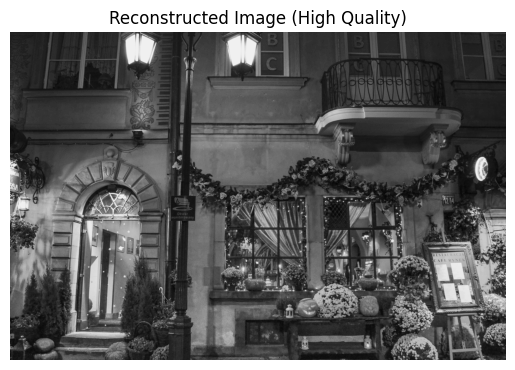

Medium Quality : PSNR = 28.385826098655563 dB , Compression Ratio = 63.21


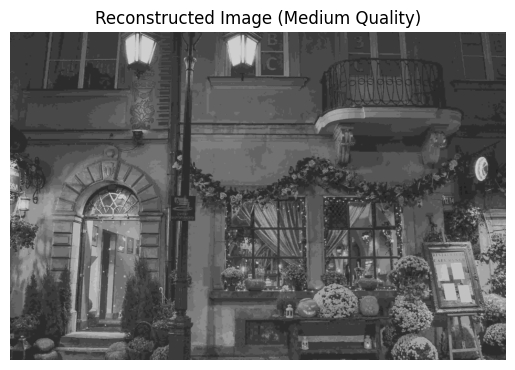

Low Quality : PSNR = 24.44628338855166 dB , Compression Ratio = 131.67


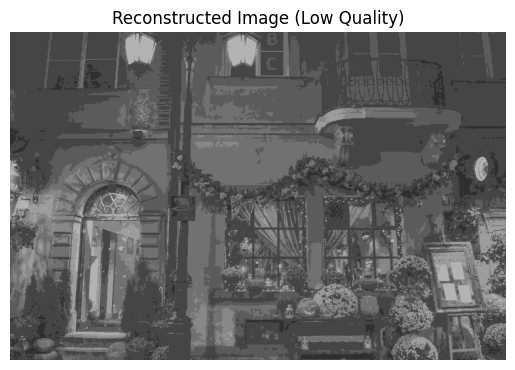

In [59]:
# 3592,2376
Q_level = {"High": 0.5, "Medium": 10, "Low": 20}
for level in Q_level:
    Q_factor = Q_level[level]
    image = cv2.imread('image1.jpg', cv2.IMREAD_GRAYSCALE)
    image = cv2.resize(image, (3592,2376))
    # print(image.shape)
    macroblocksize = 8
    macroblocks = DevideToMacroblocks(image, macroblocksize)
    dctblocks = dct(macroblocks)
    quantized_dctblocks = Quantize(dctblocks, Q_factor)
    dc_coefficients = dc_extract(quantized_dctblocks)
    ac_coefficients = ac_extract(quantized_dctblocks)
    dpcm_encoded = dpcm(dc_coefficients)
    runlength_encoded = runlength(ac_coefficients)

    dc_frequencies = Counter(dpcm_encoded)
    dc_huffman_tree = build_huffman_tree(dc_frequencies)
    dc_huffman_dict = generate_huffman_codes(dc_huffman_tree)
    dc_huffman_dict = {int(k): v for k, v in dc_huffman_dict.items()}
    dc_huffman_encoded_data = huffman_encode(dpcm_encoded, dc_huffman_dict)
    filename = f"Image1_huffman_encoded_dc_datastream_{level}_quality.txt"
    with open(filename, "w") as file:
        json.dump({"encoded_text": dc_huffman_encoded_data, "huffman_dict": dc_huffman_dict}, file)

    ac_frequencies = Counter(runlength_encoded)
    ac_huffman_tree = build_huffman_tree(ac_frequencies)
    ac_huffman_dict = generate_huffman_codes(ac_huffman_tree)
    ac_huffman_dict = {int(k): v for k, v in ac_huffman_dict.items()}
    ac_huffman_encoded_data = huffman_encode(runlength_encoded, ac_huffman_dict)
    filename = f"Image1_huffman_encoded_ac_datastream_{level}_quality.txt"
    with open(filename, "w") as file:
        json.dump({"encoded_text": ac_huffman_encoded_data, "huffman_dict": ac_huffman_dict}, file)

    dc_huffman_decoded_data = huffman_decode(dc_huffman_encoded_data, dc_huffman_dict)
    ac_huffman_decoded_data = huffman_decode(ac_huffman_encoded_data, ac_huffman_dict)

    dpcm_decoded = inverse_dpcm(dc_huffman_decoded_data)
    ac_decoded = inverse_runlength(ac_huffman_decoded_data)

    inverse_zigzag_blocks = []
    for i in range(len(ac_decoded)):
        zigzag_array = np.insert(ac_decoded[i], 0, dpcm_decoded[i])
        inverse_zigzag_block = inverse_zigzag_scan(zigzag_array)
        inverse_zigzag_blocks.append(inverse_zigzag_block)

    dequantized_blocks = deQuantize(inverse_zigzag_blocks, Q_factor)
    inverse_dct_blocks = inverse_dct(dequantized_blocks)
    reconstructed_image = reconstruct_image(inverse_dct_blocks, image.shape, macroblocksize)
    psnr = calculate_psnr(image, reconstructed_image)
    compression_ratio = calculate_compression_ratio(image, dc_huffman_encoded_data + ac_huffman_encoded_data)
    print(f"{level} Quality : PSNR = {psnr} dB , Compression Ratio = {np.round(compression_ratio,2)}")
    cv2.imwrite(f"Image1_reconstructed_{level}.jpg", reconstructed_image)
    plt.imshow(reconstructed_image, cmap='gray')
    plt.axis('off')
    plt.title(f"Reconstructed Image ({level} Quality)")
    plt.show()


# 3.1.2

In [60]:
target_bit_rate = (312+300) * 1000 

target_size_bits = target_bit_rate

# Function to calculate the size of the encoded data
def calculate_encoded_size(dc_huffman_encoded_data, ac_huffman_encoded_data):
    return len(dc_huffman_encoded_data) + len(ac_huffman_encoded_data)

# Function to adjust the quantization factor to meet the target size
def adjust_quantization_factor(image, macroblocksize, target_size_bits):
    Q_factor = 1
    step = 1.5
    tolerance = 0.01 * target_size_bits  # 5% tolerance

    while True:
        macroblocks = DevideToMacroblocks(image, macroblocksize)
        dctblocks = dct(macroblocks)
        quantized_dctblocks = Quantize(dctblocks, Q_factor)
        dc_coefficients = dc_extract(quantized_dctblocks)
        ac_coefficients = ac_extract(quantized_dctblocks)
        dpcm_encoded = dpcm(dc_coefficients)
        runlength_encoded = runlength(ac_coefficients)

        dc_frequencies = Counter(dpcm_encoded)
        dc_huffman_tree = build_huffman_tree(dc_frequencies)
        dc_huffman_dict = generate_huffman_codes(dc_huffman_tree)
        dc_huffman_dict = {int(k): v for k, v in dc_huffman_dict.items()}
        dc_huffman_encoded_data = huffman_encode(dpcm_encoded, dc_huffman_dict)

        ac_frequencies = Counter(runlength_encoded)
        ac_huffman_tree = build_huffman_tree(ac_frequencies)
        ac_huffman_dict = generate_huffman_codes(ac_huffman_tree)
        ac_huffman_dict = {int(k): v for k, v in ac_huffman_dict.items()}
        ac_huffman_encoded_data = huffman_encode(runlength_encoded, ac_huffman_dict)

        encoded_size = calculate_encoded_size(dc_huffman_encoded_data, ac_huffman_encoded_data)
        print(Q_factor, encoded_size, target_size_bits)

        if abs(encoded_size - target_size_bits) <= tolerance:
            break
        elif encoded_size > target_size_bits:
            Q_factor += step
        else:
            Q_factor -= step
        
        step = max(0.1, step * 0.9) if abs(encoded_size - target_size_bits) < tolerance * 2 else min(1, step * 1.1)

    return Q_factor, dc_huffman_encoded_data, ac_huffman_encoded_data, dc_huffman_dict, ac_huffman_dict

# Load the image
image = cv2.imread('image1.jpg', cv2.IMREAD_GRAYSCALE)
image = cv2.resize(image, (3592,2376))
macroblocksize = 8

# Adjust the quantization factor to meet the target size
Q_factor, dc_huffman_encoded_data, ac_huffman_encoded_data, dc_huffman_dict, ac_huffman_dict = adjust_quantization_factor(image, macroblocksize, target_size_bits)

# Decode the image using the adjusted quantization factor
dc_huffman_decoded_data = huffman_decode(dc_huffman_encoded_data, dc_huffman_dict)
ac_huffman_decoded_data = huffman_decode(ac_huffman_encoded_data, ac_huffman_dict)

dpcm_decoded = inverse_dpcm(dc_huffman_decoded_data)
ac_decoded = inverse_runlength(ac_huffman_decoded_data)

inverse_zigzag_blocks = []
for i in range(len(ac_decoded)):
    zigzag_array = np.insert(ac_decoded[i], 0, dpcm_decoded[i])
    inverse_zigzag_block = inverse_zigzag_scan(zigzag_array)
    inverse_zigzag_blocks.append(inverse_zigzag_block)

print("Q_factor",Q_factor)
dequantized_blocks = deQuantize(inverse_zigzag_blocks, Q_factor)
inverse_dct_blocks = inverse_dct(dequantized_blocks)
reconstructed_image = reconstruct_image(inverse_dct_blocks, image.shape, macroblocksize)

# Calculate PSNR
psnr = calculate_psnr(image, reconstructed_image)
compression_ratio = calculate_compression_ratio(image, dc_huffman_encoded_data + ac_huffman_encoded_data)

print(f"Adjusted Quality : PSNR = {psnr} dB , Compression Ratio = {np.round(compression_ratio, 2)}")
cv2.imwrite(f"Image1_reconstructed_adjusted.jpg", reconstructed_image)

1 7320969 612000
2.5 3599721 612000
3.5 2721461 612000
4.5 2198743 612000
5.5 1854690 612000
6.5 1600792 612000
7.5 1408747 612000
8.5 1259068 612000
9.5 1134803 612000
10.5 1030511 612000
11.5 942012 612000
12.5 865002 612000
13.5 798430 612000
14.5 739194 612000
15.5 688661 612000
16.5 644396 612000
17.5 603951 612000
16.5 644396 612000
17.4 608138 612000
Q_factor 17.4
Adjusted Quality : PSNR = 25.191715277015724 dB , Compression Ratio = 112.27


True

Target bit rate = (312+300)*1000
Target compression ratio = 8 * image_size / Target_bit_rate
                         = 8 * 3596 * 2376 / (312+300) * 1000
                         = 111.68

In [61]:
#Q_factor adjusted manually  based on the compression ratio
Q_factor = 17.3
image = cv2.imread('image1.jpg', cv2.IMREAD_GRAYSCALE)
image = cv2.resize(image, (3592,2376))
macroblocksize = 8
macroblocks = DevideToMacroblocks(image, macroblocksize)
dctblocks = dct(macroblocks)
quantized_dctblocks = Quantize(dctblocks, Q_factor)
dc_coefficients = dc_extract(quantized_dctblocks)
ac_coefficients = ac_extract(quantized_dctblocks)
dpcm_encoded = dpcm(dc_coefficients)
runlength_encoded = runlength(ac_coefficients)

dc_frequencies = Counter(dpcm_encoded)
dc_huffman_tree = build_huffman_tree(dc_frequencies)
dc_huffman_dict = generate_huffman_codes(dc_huffman_tree)
dc_huffman_dict = {int(k): v for k, v in dc_huffman_dict.items()}
dc_huffman_encoded_data = huffman_encode(dpcm_encoded, dc_huffman_dict)
filename = f"Image1_huffman_encoded_dc_datastream_best_quality.txt"
with open(filename, "w") as file:
    json.dump({"encoded_text": dc_huffman_encoded_data, "huffman_dict": dc_huffman_dict}, file)

ac_frequencies = Counter(runlength_encoded)
ac_huffman_tree = build_huffman_tree(ac_frequencies)
ac_huffman_dict = generate_huffman_codes(ac_huffman_tree)
ac_huffman_dict = {int(k): v for k, v in ac_huffman_dict.items()}
ac_huffman_encoded_data = huffman_encode(runlength_encoded, ac_huffman_dict)
filename = f"Image1_huffman_encoded_ac_datastream_best_quality.txt"
with open(filename, "w") as file:
    json.dump({"encoded_text": ac_huffman_encoded_data, "huffman_dict": ac_huffman_dict}, file)

dc_huffman_decoded_data = huffman_decode(dc_huffman_encoded_data, dc_huffman_dict)
ac_huffman_decoded_data = huffman_decode(ac_huffman_encoded_data, ac_huffman_dict)

dpcm_decoded = inverse_dpcm(dc_huffman_decoded_data)
ac_decoded = inverse_runlength(ac_huffman_decoded_data)

inverse_zigzag_blocks = []
for i in range(len(ac_decoded)):
    zigzag_array = np.insert(ac_decoded[i], 0, dpcm_decoded[i])
    inverse_zigzag_block = inverse_zigzag_scan(zigzag_array)
    inverse_zigzag_blocks.append(inverse_zigzag_block)

dequantized_blocks = deQuantize(inverse_zigzag_blocks, Q_factor)
inverse_dct_blocks = inverse_dct(dequantized_blocks)
reconstructed_image = reconstruct_image(inverse_dct_blocks, image.shape, macroblocksize)
psnr = calculate_psnr(image, reconstructed_image)
compression_ratio = calculate_compression_ratio(image, dc_huffman_encoded_data + ac_huffman_encoded_data)
print(f"Best Quality : PSNR = {psnr} dB , Compression Ratio = {np.round(compression_ratio,2)}")
cv2.imwrite(f"Image1_reconstructed_best.jpg", reconstructed_image)

Best Quality : PSNR = 25.22245837411962 dB , Compression Ratio = 111.59


True

# 3.1.3

In [62]:
target_bit_rate = 500 #enter the traget bit rate in kbps
target_size_bits = target_bit_rate *1000

# Function to calculate the size of the encoded data
def calculate_encoded_size(dc_huffman_encoded_data, ac_huffman_encoded_data):
    return len(dc_huffman_encoded_data) + len(ac_huffman_encoded_data)

# Function to adjust the quantization factor to meet the target size
def adjust_quantization_factor(image, macroblocksize, target_size_bits):
    Q_factor = 1
    step = 1.5
    tolerance = 0.01 * target_size_bits  # 1% tolerance

    while True:

        macroblocks = DevideToMacroblocks(image, macroblocksize)
        dctblocks = dct(macroblocks)
        quantized_dctblocks = Quantize(dctblocks, Q_factor)
        dc_coefficients = dc_extract(quantized_dctblocks)
        ac_coefficients = ac_extract(quantized_dctblocks)
        dpcm_encoded = dpcm(dc_coefficients)
        runlength_encoded = runlength(ac_coefficients)

        dc_frequencies = Counter(dpcm_encoded)
        dc_huffman_tree = build_huffman_tree(dc_frequencies)
        dc_huffman_dict = generate_huffman_codes(dc_huffman_tree)
        dc_huffman_dict = {int(k): v for k, v in dc_huffman_dict.items()}
        dc_huffman_encoded_data = huffman_encode(dpcm_encoded, dc_huffman_dict)

        ac_frequencies = Counter(runlength_encoded)
        ac_huffman_tree = build_huffman_tree(ac_frequencies)
        ac_huffman_dict = generate_huffman_codes(ac_huffman_tree)
        ac_huffman_dict = {int(k): v for k, v in ac_huffman_dict.items()}
        ac_huffman_encoded_data = huffman_encode(runlength_encoded, ac_huffman_dict)

        encoded_size = calculate_encoded_size(dc_huffman_encoded_data, ac_huffman_encoded_data)
        print(Q_factor, encoded_size, target_size_bits)

        if abs(encoded_size - target_size_bits) <= tolerance:
            break
        elif encoded_size > target_size_bits:
            Q_factor += step
        else:
            Q_factor -= step
        
        step = max(0.1, step * 0.9) if abs(encoded_size - target_size_bits) < tolerance * 2 else min(1, step * 1.1)
        
    return Q_factor, dc_huffman_encoded_data, ac_huffman_encoded_data, dc_huffman_dict, ac_huffman_dict

# Load the image
image = cv2.imread('image1.jpg', cv2.IMREAD_GRAYSCALE)
image = cv2.resize(image, (3592,2376))
macroblocksize = 8

# Adjust the quantization factor to meet the target size
Q_factor, dc_huffman_encoded_data, ac_huffman_encoded_data, dc_huffman_dict, ac_huffman_dict = adjust_quantization_factor(image, macroblocksize, target_size_bits)

# Decode the image using the adjusted quantization factor
dc_huffman_decoded_data = huffman_decode(dc_huffman_encoded_data, dc_huffman_dict)
ac_huffman_decoded_data = huffman_decode(ac_huffman_encoded_data, ac_huffman_dict)

dpcm_decoded = inverse_dpcm(dc_huffman_decoded_data)
ac_decoded = inverse_runlength(ac_huffman_decoded_data)

inverse_zigzag_blocks = []
for i in range(len(ac_decoded)):
    zigzag_array = np.insert(ac_decoded[i], 0, dpcm_decoded[i])
    inverse_zigzag_block = inverse_zigzag_scan(zigzag_array)
    inverse_zigzag_blocks.append(inverse_zigzag_block)

dequantized_blocks = deQuantize(inverse_zigzag_blocks, Q_factor)
inverse_dct_blocks = inverse_dct(dequantized_blocks)
reconstructed_image = reconstruct_image(inverse_dct_blocks, image.shape, macroblocksize)

# Calculate PSNR and compression ratio
psnr = calculate_psnr(image, reconstructed_image)
compression_ratio = calculate_compression_ratio(image, dc_huffman_encoded_data + ac_huffman_encoded_data)

print("Q_factor",Q_factor)
print(f"Adjusted Quality : PSNR = {psnr} dB , Compression Ratio = {np.round(compression_ratio, 2)}")
cv2.imwrite(f"Image1_reconstructed_{target_bit_rate}.jpg", reconstructed_image)

1 7320969 500000
2.5 3599721 500000
3.5 2721461 500000
4.5 2198743 500000
5.5 1854690 500000
6.5 1600792 500000
7.5 1408747 500000
8.5 1259068 500000
9.5 1134803 500000
10.5 1030511 500000
11.5 942012 500000
12.5 865002 500000
13.5 798430 500000
14.5 739194 500000
15.5 688661 500000
16.5 644396 500000
17.5 603951 500000
18.5 567474 500000
19.5 533485 500000
20.5 504351 500000
Q_factor 20.5
Adjusted Quality : PSNR = 24.293229526213516 dB , Compression Ratio = 135.38


True